# 🧠 Emotion Detector — Member 2 Training Notebook

**Pipeline:** Baseline → BiLSTM Tuning → DistilBERT Tuning → Evaluation → Visualizations

> **Before running:** Set runtime to **GPU** → Runtime → Change runtime type → T4 GPU

## 📁 Step 1: Clone Repo & Set Project Path


In [ ]:
import os, sys
from google.colab import userdata

REPO   = 'github.com/l242585-ai/Emotion_Detector.git'
BRANCH = 'main'
PROJECT_PATH = '/content/Emotion_Detector'

try:
    token = userdata.get('GITHUB_TOKEN')
    URL = f'https://{token}@{REPO}'
except Exception:
    URL = f'https://{REPO}'

os.chdir('/content')
if not os.path.exists(f'{PROJECT_PATH}/.git'):
    !git clone -b {BRANCH} {URL} {PROJECT_PATH}
else:
    !git -C {PROJECT_PATH} pull origin {BRANCH}

os.chdir(PROJECT_PATH)
sys.path.insert(0, PROJECT_PATH)
print('📍', os.getcwd())
print('📂', os.listdir())

Cloning into '/content/Emotion_Detector'...
remote: Enumerating objects: 123, done.
remote: Counting objects: 100% (123/123), done.
remote: Compressing objects: 100% (95/95), done.
remote: Total 123 (delta 32), reused 100 (delta 18), pack-reused 0 (from 0)
Receiving objects: 100% (123/123), 4.34 MiB | 26.61 MiB/s, done.
Resolving deltas: 100% (32/32), done.
📍 /content/Emotion_Detector
📂 ['TASK_DIVISION.md', 'Reports', '.kiro', 'create_architecture_diagram.py', '.gitignore', 'figures', 'DELIVERABLE_2_TASKS.md', 'src', 'Emotion_Detector_Training.ipynb', 'Data_Scripts', '.git', 'COLAB_INSTRUCTIONS.md', 'README.md', 'requirements.txt', 'test_preprocessing.py', 'report', 'run_member2.py', 'results', 'ARCHITECTURE.md', 'models']


In [17]:
import os
!pip install datasets --quiet

if not os.path.exists('data/processed'):
    !python Data_Scripts/01_download_data.py
    !python Data_Scripts/02_clean_data.py
else:
    print('✅ data already exists')

!ls data/processed

README.md: 100% 9.05k/9.05k [00:00<00:00, 17.5MB/s]

split/train-00000-of-00001.parquet: downloading bytes:  61% 629k/1.03M [00:00<00:00, 1.91MB/s]
split/train-00000-of-00001.parquet: downloading bytes: 100% 1.03M/1.03M [00:00<00:00, 2.86MB/s,  102kB/s  ]
split/train-00000-of-00001.parquet: reconstructing file: 100% 1.03M/1.03M [00:00<00:00, 2.87MB/s,  102kB/s  ]

split/validation-00000-of-00001.parquet: downloading bytes:   0% 0.00/127k [00:00<?, ?B/s]
split/validation-00000-of-00001.parquet: downloading bytes:  85% 108k/127k [00:00<00:00, 255kB/s]
split/validation-00000-of-00001.parquet: downloading bytes: 100% 127k/127k [00:00<00:00, 237kB/s, 12.5kB/s  ]
split/validation-00000-of-00001.parquet: reconstructing file: 100% 127k/127k [00:00<00:00, 238kB/s, 12.6kB/s  ]

split/test-00000-of-00001.parquet: downloading bytes:   0% 0.00/129k [00:00<?, ?B/s]
split/test-00000-of-00001.parquet: downloading bytes: 100% 129k/129k [00:00<00:00, 472kB/s, 12.8kB/s  ]
split/test-00000-of-00001.parque

## 📦 Step 2: Install Dependencies

In [3]:

!pip install transformers --quiet
!pip install scikit-learn pandas numpy matplotlib seaborn tqdm --quiet
print('✅ All packages installed!')

✅ All packages installed!


## 🔍 Step 3: Verify Environment

In [4]:
import torch
import sys
sys.path.insert(0, PROJECT_PATH)

print(f'PyTorch version  : {torch.__version__}')
print(f'CUDA available   : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU              : {torch.cuda.get_device_name(0)}')
    print(f'GPU Memory       : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('⚠️  No GPU! Go to Runtime → Change runtime type → GPU')

# Quick data check
from src.utils.data_loader import load_emotion_data
train, train_l, val, val_l, test, test_l = load_emotion_data()
print(f'\n✅ Data loaded: {len(train)} train | {len(val)} val | {len(test)} test')

PyTorch version  : 2.14.1+cu130
CUDA available   : True
GPU              : Tesla T4
GPU Memory       : 15.6 GB
Loading emotion dataset...
  ✓ Training samples: 15594
  ✓ Validation samples: 1958
  ✓ Test samples: 1977
  ✓ Unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

✅ Data loaded: 15594 train | 1958 val | 1977 test


---
## 🏃 Step 4: Train Baseline Model (TF-IDF + Logistic Regression)
*Fast — runs in ~30 seconds even on CPU*

In [5]:
!python src/train_baseline.py

BASELINE MODEL TRAINING: TF-IDF + Logistic Regression

[1/5] Loading data...
Loading emotion dataset...
  ✓ Training samples: 15594
  ✓ Validation samples: 1958
  ✓ Test samples: 1977
  ✓ Unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

[2/5] Analyzing class distribution...

Class weights (for handling imbalance):
  Class 0 (sadness ): weight=0.570, count=4557
  Class 1 (joy     ): weight=0.497, count=5233
  Class 2 (love    ): weight=2.063, count=1260
  Class 3 (anger   ): weight=1.238, count=2100
  Class 4 (fear    ): weight=1.374, count=1892
  Class 5 (surprise): weight=4.708, count=552

[3/5] Training baseline model...
------------------------------------------------------------
Vectorizing training data with TF-IDF...
  - Max features: 5000
  - N-gram range: (1, 2)
  - Vocabulary size: 5000
  - Feature matrix shape: (15594, 5000)

Training Logistic Regression...
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:

---
## ⚙️ Step 5: Hyperparameter Tuning — BiLSTM
*~10-15 minutes on GPU. Runs 9 experiments across 3 phases.*

In [6]:
import sys
sys.path.insert(0, PROJECT_PATH)

from src.hyperparameter_tuning import tune_bilstm
best_bilstm_config = tune_bilstm()
print('\n🏆 Best BiLSTM config:', best_bilstm_config)


HYPERPARAMETER TUNING — BiLSTM
Smart Sequential Search (3 Phases)

📌 PHASE 1: Tuning Learning Rate
   LR values: [0.0001, 0.001, 0.01]
   (batch=32, dropout=0.3 fixed)
------------------------------------------------------------

  ▶ Experiment: bilstm_lr_0.0001
BiLSTM EMOTION CLASSIFIER — TRAINING
  LR=0.0001 | Batch=32 | Dropout=0.3
  Layers=2 | Hidden=64 | Embedding=128
  Epochs=10 | Early Stop patience=3
------------------------------------------------------------

  Device: cuda

[1/5] Loading data...
Loading emotion dataset...
  ✓ Training samples: 15594
  ✓ Validation samples: 1958
  ✓ Test samples: 1977
  ✓ Unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Class weights (for handling imbalance):
  Class 0 (sadness ): weight=0.570, count=4557
  Class 1 (joy     ): weight=0.497, count=5233
  Class 2 (love    ): weight=2.063, count=1260
  Class 3 (anger   ): weight=1.238, count=2100
  Class 4 (fear    ): weight=1.374, count=1892
  Clas

  Train Loss: 1.7901 | Train Acc: 0.1779 | Val Loss: 1.7863 | Val Acc: 0.2472
  ✅ Best model saved (val_loss=1.7863)

Epoch 2/10


  Train Loss: 1.7790 | Train Acc: 0.2746 | Val Loss: 1.7744 | Val Acc: 0.3151
  ✅ Best model saved (val_loss=1.7744)

Epoch 3/10


  Train Loss: 1.7320 | Train Acc: 0.2909 | Val Loss: 1.6910 | Val Acc: 0.2901
  ✅ Best model saved (val_loss=1.6910)

Epoch 4/10


  Train Loss: 1.5549 | Train Acc: 0.3426 | Val Loss: 1.4933 | Val Acc: 0.3779
  ✅ Best model saved (val_loss=1.4933)

Epoch 5/10


  Train Loss: 1.3470 | Train Acc: 0.4024 | Val Loss: 1.3499 | Val Acc: 0.4597
  ✅ Best model saved (val_loss=1.3499)

Epoch 6/10


... (56 outputs left out)

  Train Loss: 0.1793 | Train Acc: 0.9358 | Val Loss: 0.2437 | Val Acc: 0.9213
  No improvement for 1/3 epochs

Epoch 5/10


  Train Loss: 0.1718 | Train Acc: 0.9381 | Val Loss: 0.2624 | Val Acc: 0.9162
  No improvement for 2/3 epochs

Epoch 6/10


  Train Loss: 0.1548 | Train Acc: 0.9441 | Val Loss: 0.2841 | Val Acc: 0.9244
  No improvement for 3/3 epochs

  ⏹  Early stopping triggered at epoch 6

Loading best model from epoch 3...



TEST RESULTS — BiLSTM
  Test Accuracy : 0.9024
  Test F1 Macro : 0.8635
  Test F1 Weighted: 0.9055

Classification Report:
              precision    recall  f1-score   support

     sadness       0.96      0.95      0.96       572
         joy       0.97      0.86      0.91       686
        love       0.71      0.96      0.82       159
       anger       0.89      0.91      0.90       273
        fear       0.91      0.83      0.87       223
    surprise       0.59      0.95      0.73        64

    accuracy                           0.90      1977
   macro avg       0.84      0.91      0.86      1977
weighted avg       0.92      0.90      0.91      1977

✅ Predictions saved → results/bilstm_predictions.csv
✅ History saved → results/bilstm_history.json
✅ Metrics saved → results/bilstm_metrics.json
✅ Experiment logged → experiments/hyperparameter_log.csv

  ✅ Best Dropout: 0.2 (val_acc=0.9295)

✅ BiLSTM TUNING COMPLETE — BEST CONFIGURATION
   Learning Rate : 0.01
   Batch Size    : 6

## 🔥 Step 6: Train Final BiLSTM (Best Hyperparameters)

In [7]:
from src.train_deep import train_bilstm

# Use the best config found above, or set manually:
results = train_bilstm(
    lr=best_bilstm_config['lr'],
    batch_size=best_bilstm_config['batch_size'],
    dropout=best_bilstm_config['dropout'],
    num_epochs=25,
    patience=5,
    save_path='models/best_bilstm.pth',
    log_to_csv='experiments/hyperparameter_log.csv',
    experiment_name='bilstm_final_best'
)
print('✅ BiLSTM training complete!')

BiLSTM EMOTION CLASSIFIER — TRAINING
  LR=0.01 | Batch=64 | Dropout=0.2
  Layers=2 | Hidden=64 | Embedding=128
  Epochs=25 | Early Stop patience=5
------------------------------------------------------------

  Device: cuda

[1/5] Loading data...
Loading emotion dataset...
  ✓ Training samples: 15594
  ✓ Validation samples: 1958
  ✓ Test samples: 1977
  ✓ Unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Class weights (for handling imbalance):
  Class 0 (sadness ): weight=0.570, count=4557
  Class 1 (joy     ): weight=0.497, count=5233
  Class 2 (love    ): weight=2.063, count=1260
  Class 3 (anger   ): weight=1.238, count=2100
  Class 4 (fear    ): weight=1.374, count=1892
  Class 5 (surprise): weight=4.708, count=552

[2/5] Preprocessing text...
Building vocabulary from 15594 texts...
  Total unique words: 14585
  ✓ Vocabulary size: 10000
  ✓ Most common words: ['i', 'feel', 'and', 'to', 'the', 'a', 'feeling', 'that', 'of', 'my']

[3/5] Cr

  Train Loss: 0.9843 | Train Acc: 0.6116 | Val Loss: 0.3126 | Val Acc: 0.8973
  ✅ Best model saved (val_loss=0.3126)

Epoch 2/25


  Train Loss: 0.2279 | Train Acc: 0.9157 | Val Loss: 0.2085 | Val Acc: 0.9173
  ✅ Best model saved (val_loss=0.2085)

Epoch 3/25


  Train Loss: 0.1382 | Train Acc: 0.9453 | Val Loss: 0.2384 | Val Acc: 0.9137
  No improvement for 1/5 epochs

Epoch 4/25


  Train Loss: 0.1092 | Train Acc: 0.9567 | Val Loss: 0.2642 | Val Acc: 0.9152
  No improvement for 2/5 epochs

Epoch 5/25


  Train Loss: 0.0869 | Train Acc: 0.9661 | Val Loss: 0.2682 | Val Acc: 0.9142
  No improvement for 3/5 epochs

Epoch 6/25


  Train Loss: 0.0530 | Train Acc: 0.9794 | Val Loss: 0.3197 | Val Acc: 0.9213
  No improvement for 4/5 epochs

Epoch 7/25


  Train Loss: 0.0291 | Train Acc: 0.9894 | Val Loss: 0.3792 | Val Acc: 0.9219
  No improvement for 5/5 epochs

  ⏹  Early stopping triggered at epoch 7

Loading best model from epoch 2...



TEST RESULTS — BiLSTM
  Test Accuracy : 0.9110
  Test F1 Macro : 0.8725
  Test F1 Weighted: 0.9138

Classification Report:
              precision    recall  f1-score   support

     sadness       0.97      0.93      0.95       572
         joy       0.97      0.90      0.93       686
        love       0.73      0.96      0.83       159
       anger       0.89      0.94      0.91       273
        fear       0.91      0.84      0.87       223
    surprise       0.61      0.92      0.74        64

    accuracy                           0.91      1977
   macro avg       0.85      0.91      0.87      1977
weighted avg       0.92      0.91      0.91      1977

✅ Predictions saved → results/bilstm_predictions.csv
✅ History saved → results/bilstm_history.json
✅ Metrics saved → results/bilstm_metrics.json
✅ Experiment logged → experiments/hyperparameter_log.csv
✅ BiLSTM training complete!


---
## ⚙️ Step 7: Hyperparameter Tuning — DistilBERT
*~15-25 minutes on GPU (T4). Runs 9 experiments.*

In [8]:
from src.hyperparameter_tuning import tune_distilbert
best_bert_config = tune_distilbert()
print('\n🏆 Best DistilBERT config:', best_bert_config)


HYPERPARAMETER TUNING — DistilBERT
Smart Sequential Search (3 Phases)
⚠️  Requires GPU (Google Colab recommended)

📌 PHASE 1: Tuning Learning Rate
   LR values: [1e-05, 2e-05, 5e-05]
------------------------------------------------------------

  ▶ Experiment: distilbert_lr_1e-05
DistilBERT EMOTION CLASSIFIER — FINE-TUNING
  LR=1e-05 | Batch=16 | Dropout=0.3
  Epochs=3 | MaxLen=128 | Patience=2
------------------------------------------------------------

  Device: cuda

[1/5] Loading data...
Loading emotion dataset...
  ✓ Training samples: 15594
  ✓ Validation samples: 1958
  ✓ Test samples: 1977
  ✓ Unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Class weights (for handling imbalance):
  Class 0 (sadness ): weight=0.570, count=4557
  Class 1 (joy     ): weight=0.497, count=5233
  Class 2 (love    ): weight=2.063, count=1260
  Class 3 (anger   ): weight=1.238, count=2100
  Class 4 (fear    ): weight=1.374, count=1892
  Class 5 (surprise)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]


[3/5] Creating data loaders...
  ✓ Train batches : 975
  ✓ Val batches   : 123
  ✓ Test batches  : 124

[4/5] Loading pretrained DistilBERT...


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

... (61 outputs left out)

  Train Loss: 0.6909 | Train Acc: 0.7725 | Val Loss: 0.3389 | Val Acc: 0.9224
  ✅ Best model saved (val_loss=0.3389)

Epoch 2/3


  Train Loss: 0.2305 | Train Acc: 0.9398 | Val Loss: 0.2504 | Val Acc: 0.9397
  ✅ Best model saved (val_loss=0.2504)

Epoch 3/3


  Train Loss: 0.1472 | Train Acc: 0.9594 | Val Loss: 0.2488 | Val Acc: 0.9402
  ✅ Best model saved (val_loss=0.2488)

Loading best model from epoch 3...



TEST RESULTS — DistilBERT
  Test Accuracy : 0.9297
  Test F1 Macro : 0.8855
  Test F1 Weighted: 0.9303

Classification Report:
              precision    recall  f1-score   support

     sadness       0.97      0.97      0.97       572
         joy       0.96      0.94      0.95       686
        love       0.79      0.90      0.84       159
       anger       0.93      0.94      0.93       273
        fear       0.92      0.87      0.89       223
    surprise       0.71      0.75      0.73        64

    accuracy                           0.93      1977
   macro avg       0.88      0.89      0.89      1977
weighted avg       0.93      0.93      0.93      1977

✅ Predictions saved → results/distilbert_predictions.csv
✅ History saved → results/distilbert_history.json
✅ Metrics saved → results/distilbert_metrics.json

  ✅ Best Dropout: 0.2 (val_acc=0.9413)

✅ DistilBERT TUNING COMPLETE — BEST CONFIGURATION
   Learning Rate : 2e-05
   Batch Size    : 8
   Dropout       : 0.2

🏆 Best Dist

## 🤖 Step 8: Train Final DistilBERT (Best Hyperparameters)

In [9]:
from src.train_distilbert import train_distilbert

results = train_distilbert(
    lr=best_bert_config['lr'],
    batch_size=best_bert_config['batch_size'],
    dropout=best_bert_config['dropout'],
    num_epochs=5,
    patience=3,
    save_path='models/best_distilbert.pth',
    log_to_csv='experiments/hyperparameter_log.csv',
    experiment_name='distilbert_final_best'
)
print('✅ DistilBERT fine-tuning complete!')

DistilBERT EMOTION CLASSIFIER — FINE-TUNING
  LR=2e-05 | Batch=8 | Dropout=0.2
  Epochs=5 | MaxLen=128 | Patience=3
------------------------------------------------------------

  Device: cuda

[1/5] Loading data...
Loading emotion dataset...
  ✓ Training samples: 15594
  ✓ Validation samples: 1958
  ✓ Test samples: 1977
  ✓ Unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Class weights (for handling imbalance):
  Class 0 (sadness ): weight=0.570, count=4557
  Class 1 (joy     ): weight=0.497, count=5233
  Class 2 (love    ): weight=2.063, count=1260
  Class 3 (anger   ): weight=1.238, count=2100
  Class 4 (fear    ): weight=1.374, count=1892
  Class 5 (surprise): weight=4.708, count=552

[2/5] Loading DistilBERT tokenizer...

[3/5] Creating data loaders...
  ✓ Train batches : 1950
  ✓ Val batches   : 245
  ✓ Test batches  : 248

[4/5] Loading pretrained DistilBERT...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  ✓ Total parameters    : 66,958,086
  ✓ Trainable parameters: 66,958,086

[5/5] Fine-tuning DistilBERT...
------------------------------------------------------------

Epoch 1/5


  Train Loss: 0.7512 | Train Acc: 0.7541 | Val Loss: 0.3480 | Val Acc: 0.9300
  ✅ Best model saved (val_loss=0.3480)

Epoch 2/5


  Train Loss: 0.2378 | Train Acc: 0.9370 | Val Loss: 0.3412 | Val Acc: 0.9346
  ✅ Best model saved (val_loss=0.3412)

Epoch 3/5


  Train Loss: 0.1777 | Train Acc: 0.9547 | Val Loss: 0.3971 | Val Acc: 0.9372
  No improvement for 1/3 epochs

Epoch 4/5


  Train Loss: 0.1123 | Train Acc: 0.9702 | Val Loss: 0.4125 | Val Acc: 0.9351
  No improvement for 2/3 epochs

Epoch 5/5


  Train Loss: 0.0646 | Train Acc: 0.9844 | Val Loss: 0.3829 | Val Acc: 0.9372
  No improvement for 3/3 epochs

  ⏹  Early stopping triggered at epoch 5

Loading best model from epoch 2...



TEST RESULTS — DistilBERT
  Test Accuracy : 0.9297
  Test F1 Macro : 0.8796
  Test F1 Weighted: 0.9280

Classification Report:
              precision    recall  f1-score   support

     sadness       0.97      0.96      0.97       572
         joy       0.93      0.97      0.95       686
        love       0.88      0.79      0.83       159
       anger       0.92      0.93      0.93       273
        fear       0.87      0.93      0.90       223
    surprise       0.90      0.58      0.70        64

    accuracy                           0.93      1977
   macro avg       0.91      0.86      0.88      1977
weighted avg       0.93      0.93      0.93      1977

✅ Predictions saved → results/distilbert_predictions.csv
✅ History saved → results/distilbert_history.json
✅ Metrics saved → results/distilbert_metrics.json
✅ DistilBERT fine-tuning complete!


---
## 📊 Step 9: Evaluate All Models

In [18]:

from src.evaluate_all import main as evaluate_all
evaluate_all()

EVALUATING ALL MODELS

[1/4] Loading models and generating predictions...

  → Baseline (TF-IDF + LogReg)
✓ Model loaded from models/best_baseline.pkl
Loading emotion dataset...
  ✓ Training samples: 15594
  ✓ Validation samples: 1958
  ✓ Test samples: 1977
  ✓ Unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

  → BiLSTM
  ⚠️  BiLSTM model not found at models/best_bilstm.pth
     Run: python src/train_deep.py

  → DistilBERT
  ⚠️  DistilBERT model not found at models/best_distilbert.pth
     Run: python src/train_distilbert.py (use Colab with GPU)

[2/4] Computing metrics...

  TF-IDF + LogReg (Baseline):
    Accuracy   : 0.8963
    F1 Macro   : 0.8597
    F1 Weighted: 0.8993

MODEL COMPARISON — TEST SET RESULTS
Model                    Accuracy   F1 Macro  F1 Weighted
-----------------------------------------------------------------
TF-IDF + LogReg (Baseline)     0.8963     0.8597       0.8993

[3/4] Saving predictions...


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.7.2 when using version 1.6.1. This might lead to breaking c

✅ Combined predictions → results/predictions.csv
✅ Metrics summary → results/metrics_summary.json

[4/4] Generating confusion matrices...
✅ Confusion matrices → results/confusion_matrices.png

✅ EVALUATION COMPLETE

Files created:
  ✅ results/predictions.csv
  ✅ results/metrics_summary.json
  ✅ results/confusion_matrices.png


## 📈 Step 10: Generate All Visualizations

GENERATING VISUALIZATIONS

[1/4] Training curves...
✅ Training curves → results/training_curves.png

[2/4] Model comparison bar chart...
✅ Model comparison chart → results/model_comparison.png

[3/4] Hyperparameter sensitivity plots...
✅ Hyperparameter sensitivity → results/hyperparameter_sensitivity.png

[4/4] Per-class F1 scores...
✅ Per-class F1 chart → results/per_class_f1.png

✅ ALL VISUALIZATIONS COMPLETE

Files created:
  ✅ results/training_curves.png
  ✅ results/model_comparison.png
  ✅ results/hyperparameter_sensitivity.png
  ✅ results/per_class_f1.png

📊 results/training_curves.png:


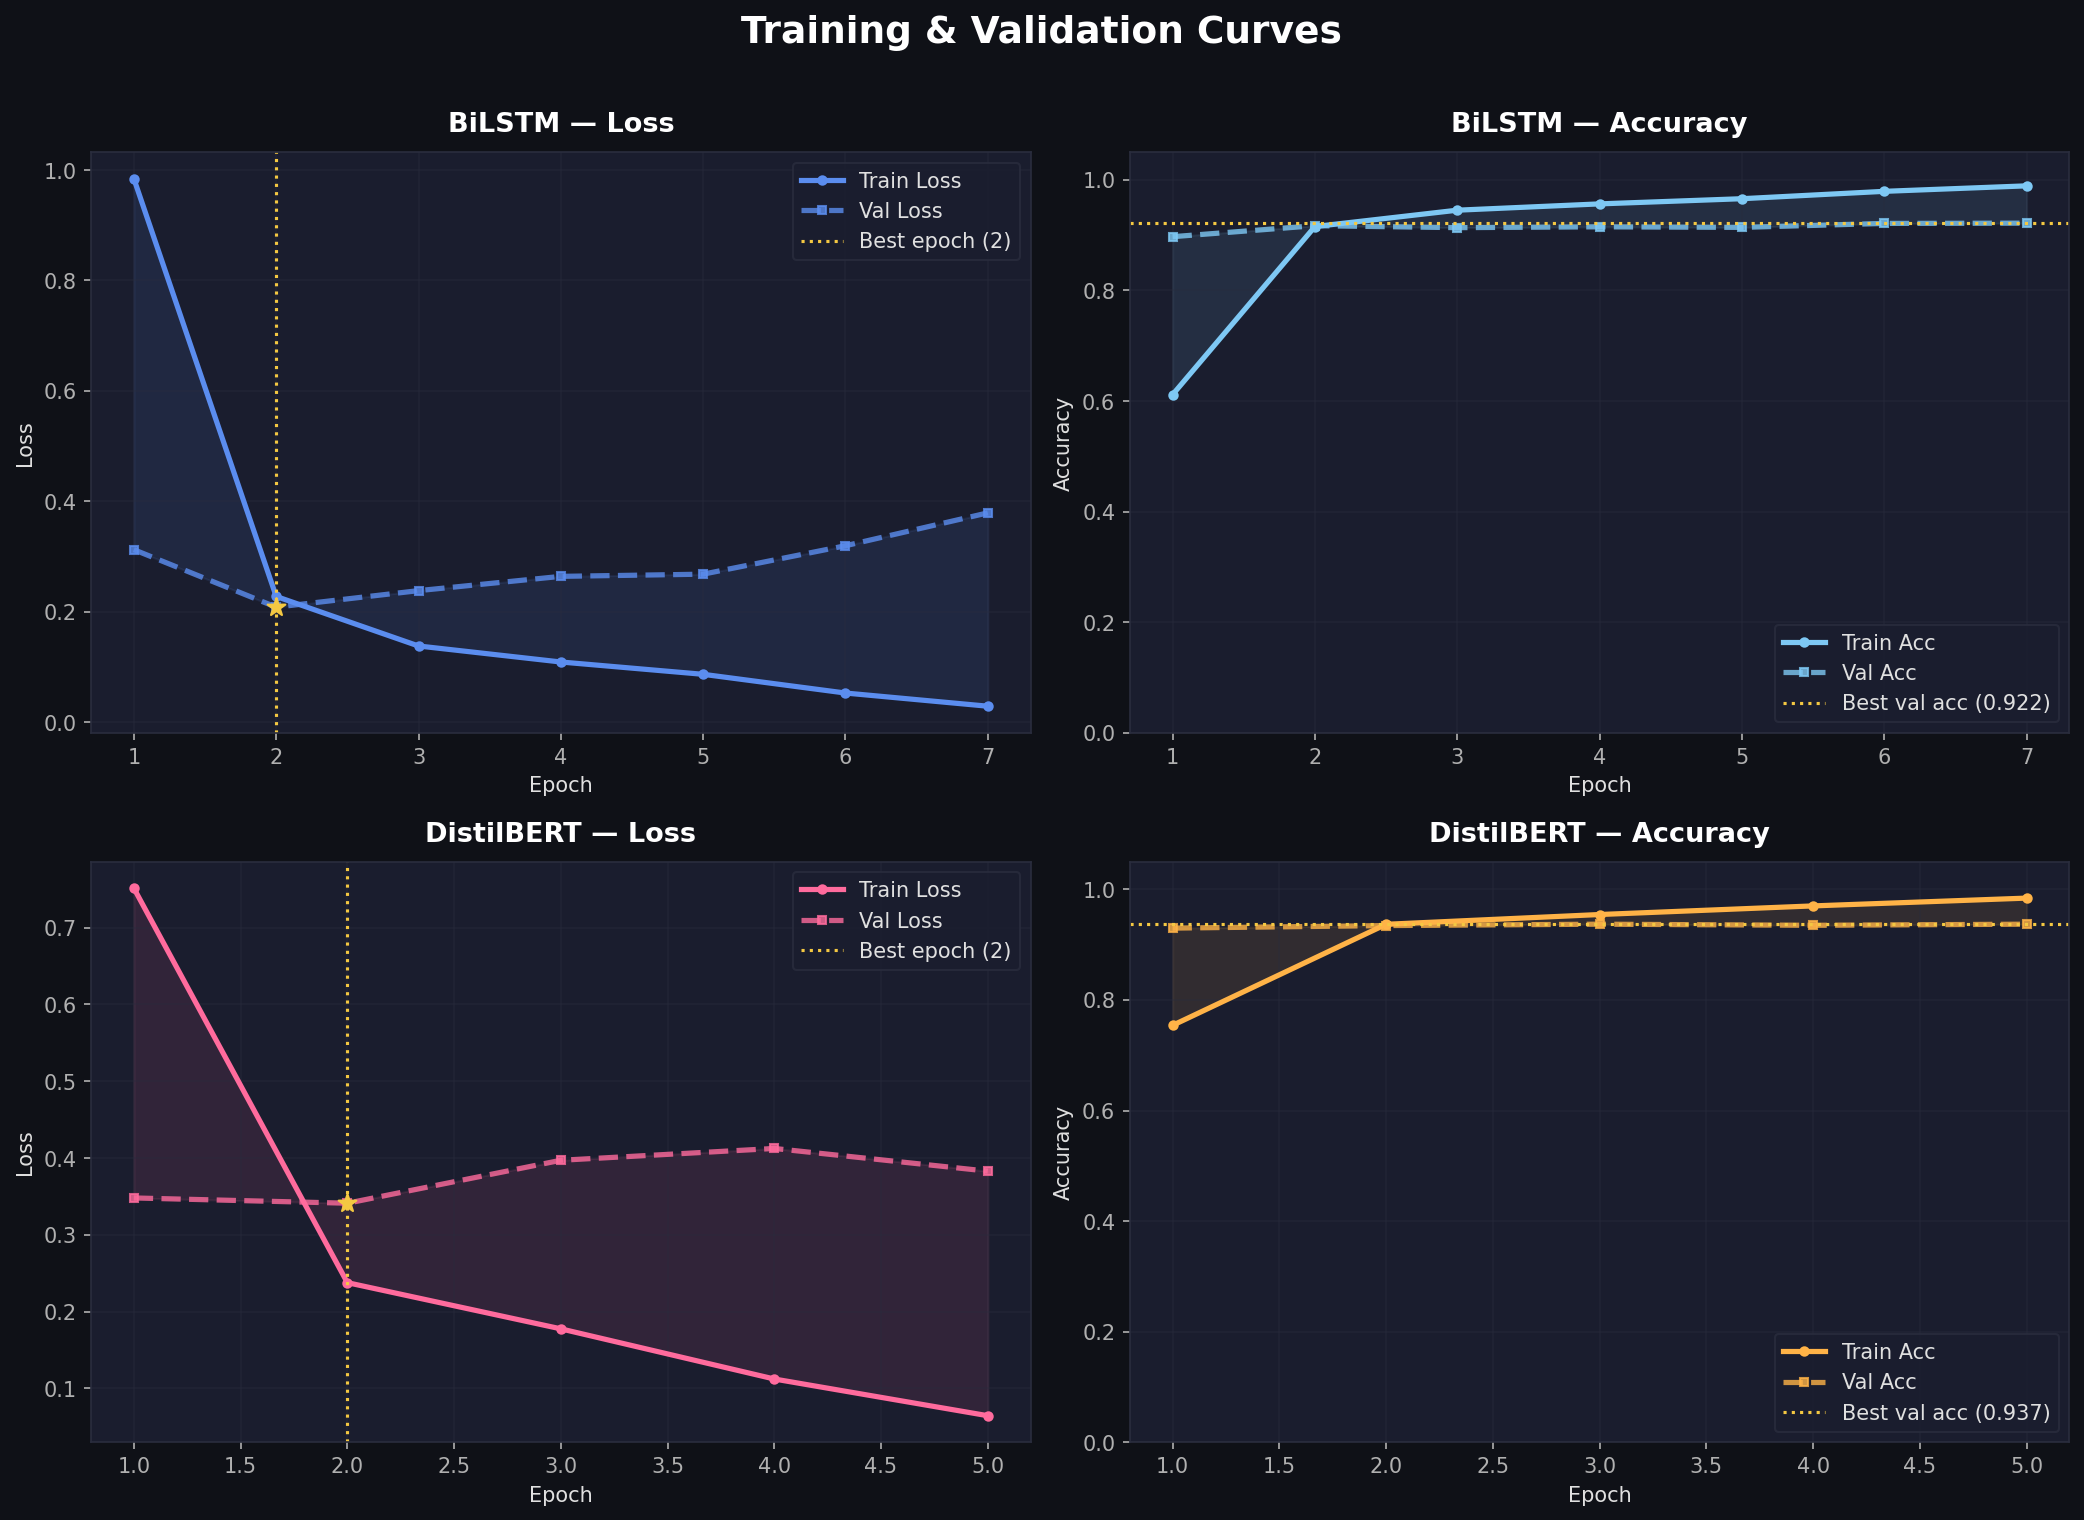


📊 results/model_comparison.png:


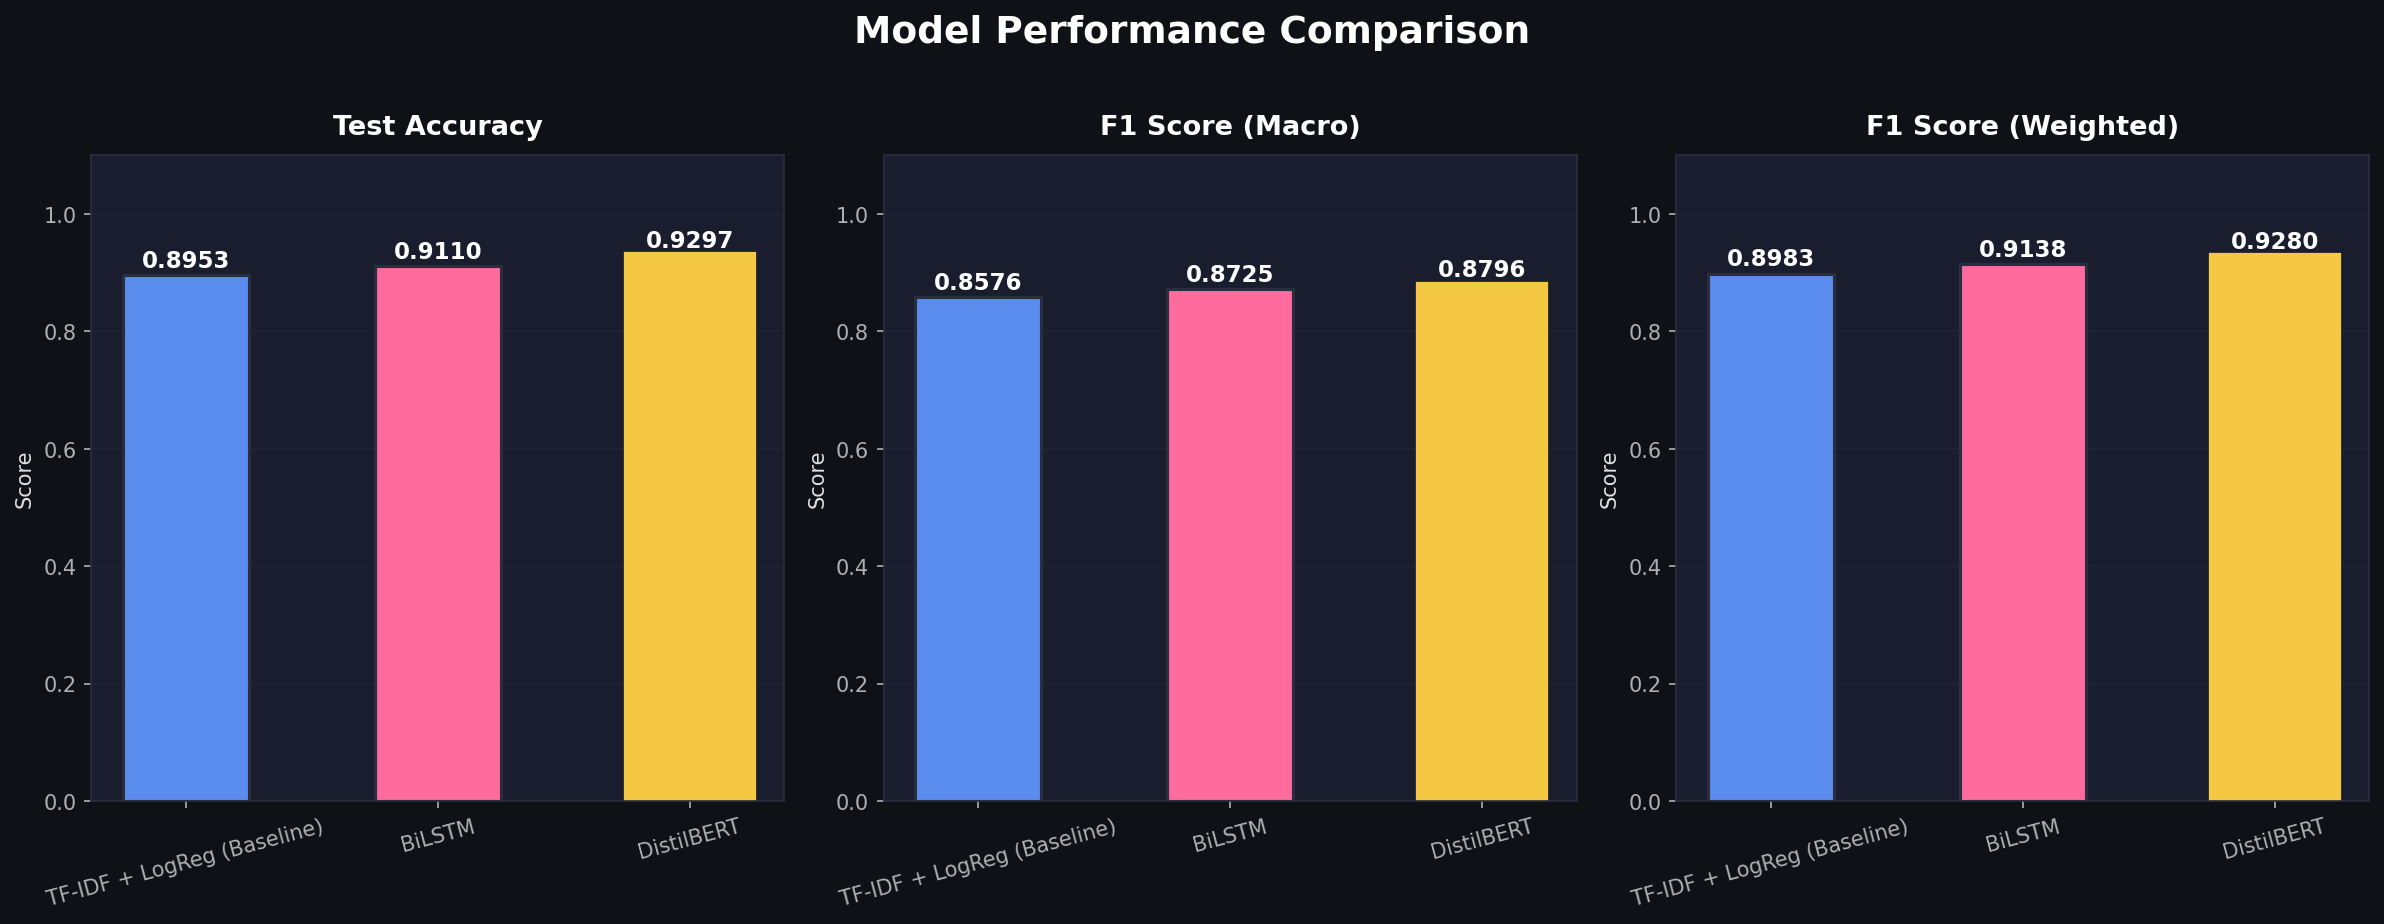


📊 results/hyperparameter_sensitivity.png:


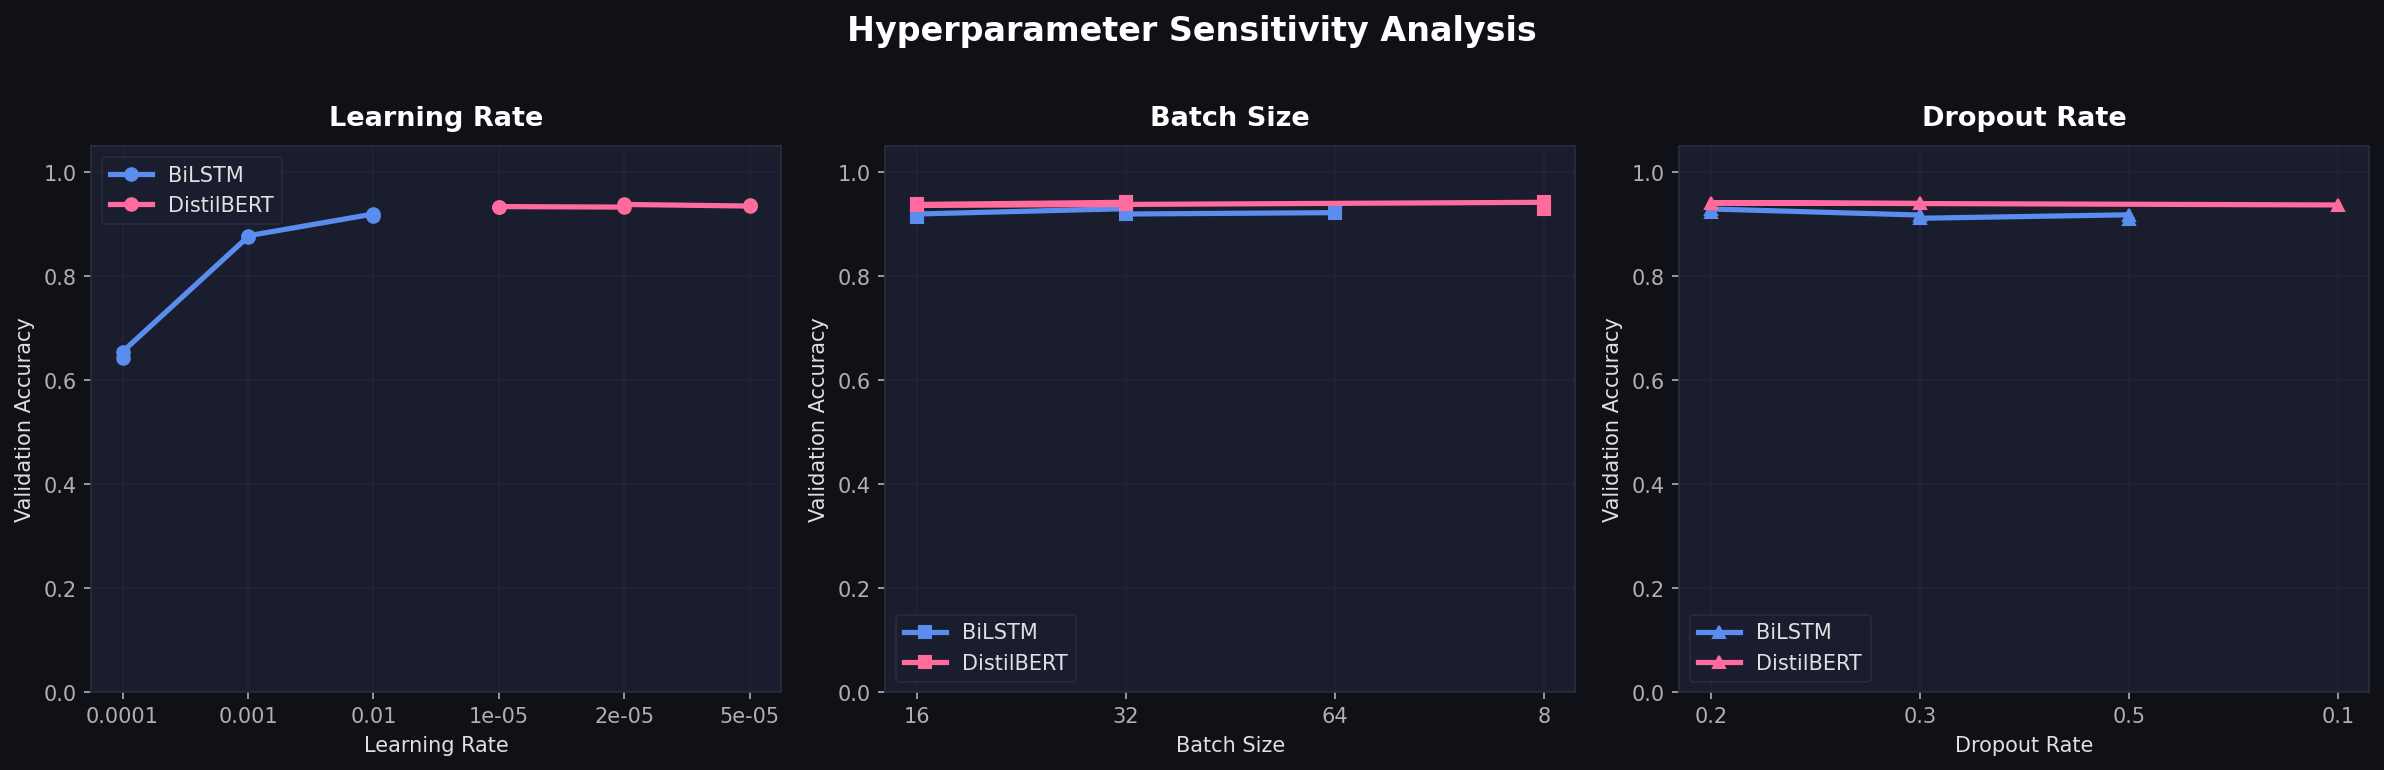


📊 results/confusion_matrices.png:


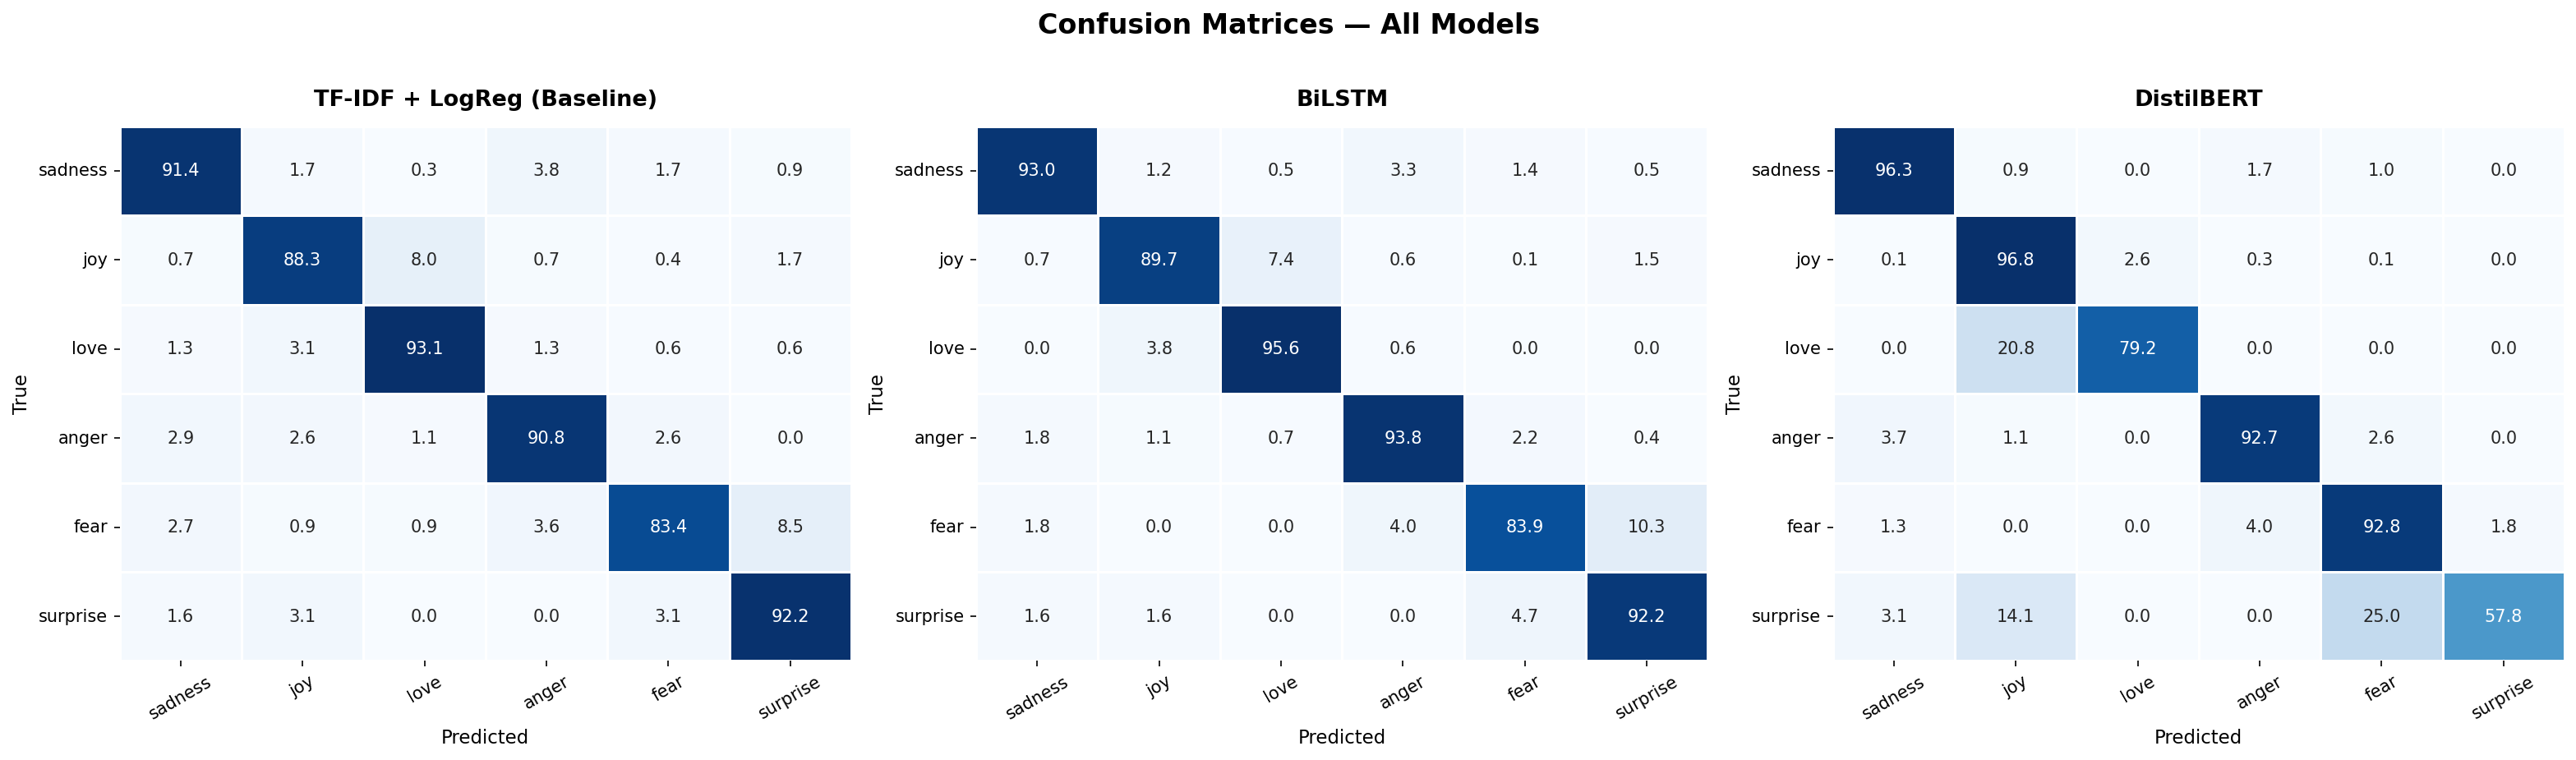


📊 results/per_class_f1.png:


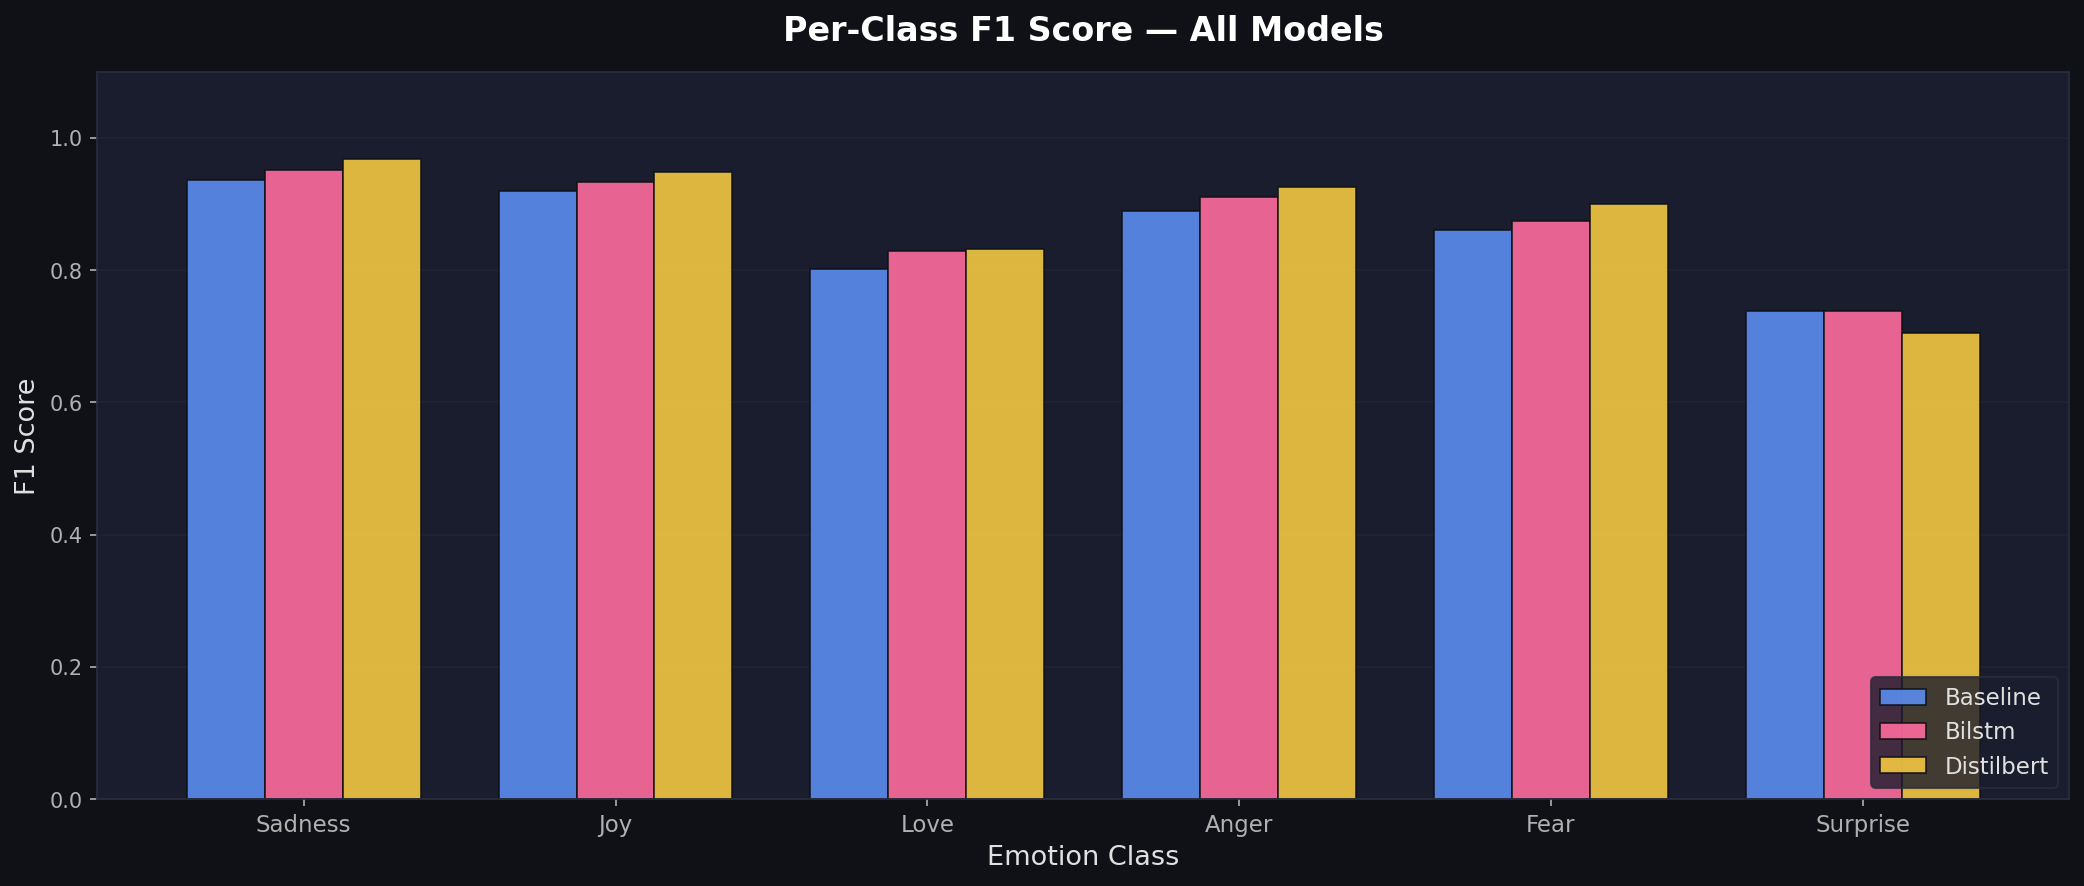

In [6]:
from src.visualize_results import main as visualize
visualize()

# Display the plots inline in Colab
from IPython.display import Image, display
import os

plots = [
    'results/training_curves.png',
    'results/model_comparison.png',
    'results/hyperparameter_sensitivity.png',
    'results/confusion_matrices.png',
    'results/per_class_f1.png',
]

for plot in plots:
    if os.path.exists(plot):
        print(f'\n📊 {plot}:')
        display(Image(plot))

---
## 📋 Step 11: View Hyperparameter Tuning Summary

In [7]:
import pandas as pd
df = pd.read_csv('experiments/hyperparameter_log.csv')

print('=== HYPERPARAMETER LOG ===')
print(df.to_string(index=False))

print('\n=== BEST PER MODEL ===')
for model in df['model'].unique():
    best = df[df['model'] == model].loc[df[df['model'] == model]['val_acc'].idxmax()]
    print(f'{model}: val_acc={best["val_acc"]:.4f} | lr={best["lr"]} | batch={best["batch_size"]} | dropout={best["dropout"]}')

=== HYPERPARAMETER LOG ===
            experiment      model      lr  batch_size  dropout  hidden_dim  num_layers  best_epoch  val_acc  val_loss  test_acc  f1_macro        timestamp
      bilstm_lr_0.0001     BiLSTM 0.00010          32      0.3          64           2          10   0.6420    0.8436    0.6343    0.6435 2026-11-08 23:12
       bilstm_lr_0.001     BiLSTM 0.00100          32      0.3          64           2           4   0.8759    0.3405    0.8670    0.8290 2026-11-08 23:13
        bilstm_lr_0.01     BiLSTM 0.01000          32      0.3          64           2           3   0.9198    0.2210    0.9074    0.8638 2026-11-08 23:13
       bilstm_batch_16     BiLSTM 0.01000          16      0.3          64           2           2   0.9132    0.2550    0.9069    0.8639 2026-11-08 23:14
       bilstm_batch_32     BiLSTM 0.01000          32      0.3          64           2           7   0.9300    0.2390    0.9226    0.8837 2026-11-08 23:16
       bilstm_batch_64     BiLSTM 0.01000  

In [10]:
import shutil, pandas as pd
shutil.copy('models/best_bilstm.pth', 'models/best_model.pth')
print(pd.read_csv('results/predictions.csv').columns.tolist())      # best_model.pth = BiLSTM copy (small enough for GitHub); DistilBERT is shared via Drive link

['text', 'true_label', 'true_emotion', 'pred_baseline', 'pred_baseline_emotion', 'correct_baseline', 'prob_baseline_sadness', 'prob_baseline_joy', 'prob_baseline_love', 'prob_baseline_anger', 'prob_baseline_fear', 'prob_baseline_surprise', 'pred_bilstm', 'pred_bilstm_emotion', 'correct_bilstm', 'prob_bilstm_sadness', 'prob_bilstm_joy', 'prob_bilstm_love', 'prob_bilstm_anger', 'prob_bilstm_fear', 'prob_bilstm_surprise', 'pred_distilbert', 'pred_distilbert_emotion', 'correct_distilbert', 'prob_distilbert_sadness', 'prob_distilbert_joy', 'prob_distilbert_love', 'prob_distilbert_anger', 'prob_distilbert_fear', 'prob_distilbert_surprise']


---
## ✅ Step 12: Deliverables Checklist

In [11]:
import os

deliverables = [
    'models/best_model.pth',
    'models/best_bilstm.pth',
    'models/best_distilbert.pth',
    'results/predictions.csv',
    'results/metrics_summary.json',
    'experiments/hyperparameter_log.csv',
    'results/training_curves.png',
    'results/model_comparison.png',
    'results/confusion_matrices.png',
    'results/per_class_f1.png',
]

print('📦 DELIVERABLES FOR MEMBER 3')
print('=' * 55)
all_ok = True
for path in deliverables:
    exists = os.path.exists(path)
    if not exists:
        all_ok = False
    print(f'{"✅" if exists else "❌"} {path}')

print('\n' + ('🎉 All deliverables ready for Member 3!' if all_ok else '⚠️  Some files missing — check above steps.'))

📦 DELIVERABLES FOR MEMBER 3
✅ models/best_model.pth
✅ models/best_bilstm.pth
✅ models/best_distilbert.pth
✅ results/predictions.csv
✅ results/metrics_summary.json
✅ experiments/hyperparameter_log.csv
✅ results/training_curves.png
✅ results/model_comparison.png
✅ results/confusion_matrices.png
✅ results/per_class_f1.png

🎉 All deliverables ready for Member 3!


In [19]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/Emotion_Detector_outputs
!cp -r models results experiments /content/drive/MyDrive/Emotion_Detector_outputs/
print('✅ Saved to your Drive: Emotion_Detector_outputs')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cp: cannot stat 'experiments': No such file or directory
✅ Saved to your Drive: Emotion_Detector_outputs


In [21]:
import os, subprocess
from google.colab import drive, userdata
drive.mount('/content/drive')

os.chdir('/content/drive/MyDrive/Projects/Emotion_Detector_git')
token = userdata.get('GITHUB_TOKEN')

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print(r.stdout + r.stderr)

def commit(paths, msg):
    sh(f'git add {paths}')
    sh(f'git diff --cached --quiet || git commit -m "{msg}"')

sh('git config user.name "Anoushay"')
sh('git config user.email "YOUR_GITHUB_EMAIL"')

commit("experiments/hyperparameter_log.csv", "feat(tuning): add BiLSTM and DistilBERT hyperparameter tuning log")
commit("models/best_bilstm.pth", "feat(train): add final BiLSTM model")
commit("models/best_model.pth", "feat(train): add best_model.pth for Member 3")
commit("results/bilstm_metrics.json results/bilstm_history.json results/bilstm_predictions.csv", "feat(eval): add BiLSTM metrics, history and predictions")
commit("results/distilbert_metrics.json results/distilbert_history.json results/distilbert_predictions.csv", "feat(eval): add DistilBERT metrics, history and predictions")
commit("results/predictions.csv results/metrics_summary.json", "feat(eval): add combined predictions and metrics summary")
commit("results/*.png", "feat(viz): add training curves, model comparison and confusion matrices")

sh('git status --short')
sh('git log --oneline -10')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


The following paths are ignored by one of your .gitignore files:
experiments/hyperparameter_log.csv
hint: Use -f if you really want to add them.
hint: Turn this message off by running
hint: "git config advice.addIgnoredFile false"



[anoushay/data-scripts e777305] feat(train): add final BiLSTM model
 1 file changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 models/best_bilstm.pth


[anoushay/data-scripts 75b7967] feat(train): add best_model.pth for Member 3
 1 file changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 models/best_model.pth

The following paths are ignored by one of your .gitignore files:
results/bilstm_predictions.csv
hint: Use -f if you really want to add them.
hint: Turn this message off by running
hint: "git config advice.addIgnoredFile false"

[anoushay/data-scripts d5782c8] feat(eval): add BiLSTM metrics, history and 

In [22]:
sh(f'git push https://{token}@github.com/l242585-ai/Emotion_Detector.git anoushay/data-scripts')

To https://github.com/l242585-ai/Emotion_Detector.git
   cabab98..0e80e77  anoushay/data-scripts -> anoushay/data-scripts

